# Week 3: Random-forest emulator for ClimateBench

Goal: learn a map from forcing (greenhouse gases and aerosol emissions) to annual-mean climate fields, then score it on the
held-out `ssp245` scenario over 2080–2100.

Run with the **Python (jcm)** kernel (`environment.yml`).

| | |
|---|---|
| **Train** | historical, hist-GHG, hist-aer, ssp126, ssp370, ssp585 |
| **Test** | ssp245 (never used for fitting, normalising, or choosing hyperparameters) |
| **Inputs per year** | CO2, CH4, and the leading 5 principal components (EOFs) of the SO2 and BC emission maps: the same features as the GP |
| **Targets** | tas, diurnal_temperature_range, pr, pr90: one forest per target, predicting every grid cell at once |
| **Hyperparameters** | random search, scored by leave-one-scenario-out cross-validation on the training scenarios |

This notebook saves its `ssp245` predictions to `results/rf_ssp245.nc`. The scoring against the paper and the other
baselines (Task 5) is in `Week3_Leaderboard.ipynb`, using the shared metric code in `metrics.py`.

In [1]:
import os
import sys
import time

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import ParameterSampler

REPO = os.path.abspath("..")          # this notebook lives in <repo>/notebooks
assert os.path.exists(f"{REPO}/metrics.py"), "run from the notebooks/ folder"
sys.path.insert(0, REPO)
from metrics import TARGETS, PERIOD, nrmse  # shared with the other baselines

DATA = os.path.expanduser("~/data/climatebench")
FIGS = f"{REPO}/figures"
RESULTS = f"{REPO}/results"
os.makedirs(FIGS, exist_ok=True)
os.makedirs(RESULTS, exist_ok=True)

TRAIN = ["historical", "hist-GHG", "hist-aer", "ssp126", "ssp370", "ssp585"]
TEST = "ssp245"
N_PCS = 5          # per aerosol species, as in the paper
N_CELLS = 96 * 144

SHORT = {"tas": "tas", "diurnal_temperature_range": "dtr", "pr": "pr", "pr90": "pr90"}

assert TEST not in TRAIN

## 1. Load the data

Same loading as the GP notebook: targets are the **ensemble mean** over members, and precipitation is converted from
kg m⁻² s⁻¹ to mm/day (× 86400), the unit the leaderboard expects.

In [2]:
def load_inputs(exp):
    return xr.open_dataset(f"{DATA}/inputs_{exp}.nc")


def load_outputs(exp):
    ds = xr.open_dataset(f"{DATA}/outputs_{exp}.nc")[TARGETS]
    ds["pr"] = ds["pr"] * 86400
    ds["pr90"] = ds["pr90"] * 86400
    return ds


inputs = {exp: load_inputs(exp) for exp in TRAIN + [TEST]}
outputs = {exp: load_outputs(exp) for exp in TRAIN + [TEST]}

# training targets: (years, grid cells) ensemble means per experiment and target
Y = {exp: {var: outputs[exp][var].mean("member").values.reshape(-1, N_CELLS) for var in TARGETS} for exp in TRAIN}
truth = outputs[TEST].mean("member")       # ssp245 ensemble mean: only for scoring and plots

for exp in TRAIN + [TEST]:
    print(f"{exp:10s} years {int(inputs[exp].time[0])}-{int(inputs[exp].time[-1])}, "
          f"members {outputs[exp].sizes['member']}")

historical years 1850-2014, members 3
hist-GHG   years 1850-2014, members 3
hist-aer   years 1850-2014, members 3
ssp126     years 2015-2100, members 1
ssp370     years 2015-2100, members 3
ssp585     years 2015-2100, members 1
ssp245     years 2015-2100, members 3


## 2. Features: the same as the GP

The PCA code is copied from `Week3_GaussianProcess.ipynb` (section 2), so both emulators see identical inputs:
√cos(latitude)-weighted maps, training mean removed, 5 components per species, each PC divided by its training std.

One change: the PCA is a function of **which scenarios it is fit on**. In the cross-validation below it is refit
without the held-out scenario, so a held-out scenario never shapes its own features. The final model fits it on all six
training scenarios; `ssp245` is only projected.

The GP also standardises every feature column. A tree only compares a feature with thresholds, so rescaling a feature
does not change the forest; this notebook skips that step.

In [3]:
def fit_pca(fields, n=N_PCS):
    # fields: training maps stacked along time, shape (time, latitude, longitude)
    w = np.sqrt(np.cos(np.deg2rad(fields.latitude.values)))
    w = np.repeat(w, fields.sizes["longitude"])            # one weight per flattened grid cell
    X = fields.values.reshape(fields.sizes["time"], -1) * w
    mean = X.mean(axis=0)
    _, s, vt = np.linalg.svd(X - mean, full_matrices=False)
    components = vt[:n]
    scale = ((X - mean) @ components.T).std(axis=0)
    explained = s[:n] ** 2 / np.sum(s ** 2)
    return {"w": w, "mean": mean, "components": components, "scale": scale, "explained": explained}


def project(pca, fields):
    X = fields.values.reshape(fields.sizes["time"], -1) * pca["w"]
    return (X - pca["mean"]) @ pca["components"].T / pca["scale"]


def fit_pcas(exps):
    return {name: fit_pca(xr.concat([inputs[e][name] for e in exps], dim="time")) for name in ["SO2", "BC"]}


def features(exp, pcas):
    cols = {"CO2": inputs[exp]["CO2"].values, "CH4": inputs[exp]["CH4"].values}
    for name in ["SO2", "BC"]:
        pcs = project(pcas[name], inputs[exp][name])
        for i in range(N_PCS):
            cols[f"{name}_{i}"] = pcs[:, i]
    return pd.DataFrame(cols, index=inputs[exp].time.values)


FEATURES = list(features(TRAIN[0], fit_pcas(TRAIN)).columns)
print(FEATURES)

['CO2', 'CH4', 'SO2_0', 'SO2_1', 'SO2_2', 'SO2_3', 'SO2_4', 'BC_0', 'BC_1', 'BC_2', 'BC_3', 'BC_4']


## 3. A forest that fits in memory

`RandomForestRegressor` handles many outputs at once: each split minimises the squared error summed over all 13,824 grid
cells, so one forest per target predicts the whole map. Every tree node then stores 13,824 values: about **100 MB per
tree** with the default `min_samples_leaf=1`. 200 trees would need ~20 GB.

A random forest predicts the **mean of its trees**, so building the trees in batches of 25, keeping only each batch's
prediction, and averaging gives the same result as one big forest, with a fraction of the memory. Feature importances
average the same way.

Grid cells are not area-weighted inside the forest (sklearn has no per-output weights), and they are not standardised,
so cells with large changes (e.g. high-latitude warming, tropical rainfall) drive the splits most.

In [4]:
def fit_predict(params, X_train, Y_train, X_test, n_trees, seed, batch=25):
    # mean prediction and feature importances of an n_trees forest, built `batch` trees at a time
    sizes = [batch] * (n_trees // batch) + ([n_trees % batch] if n_trees % batch else [])
    seeds = np.random.SeedSequence(seed).generate_state(len(sizes))
    pred, importance = 0.0, 0.0
    for size, s in zip(sizes, seeds):
        rf = RandomForestRegressor(n_estimators=size, random_state=int(s), n_jobs=-1, **params)
        rf.fit(X_train, Y_train)
        pred = pred + rf.predict(X_test) * size
        importance = importance + rf.feature_importances_ * size
        del rf
    return pred / n_trees, importance / n_trees


# cos(latitude) weights per flattened grid cell (taken from a training file; every file has the same grid)
CELL_W = np.repeat(np.cos(np.deg2rad(outputs[TRAIN[0]].lat.values)), outputs[TRAIN[0]].sizes["lon"])
CELL_W = CELL_W / CELL_W.sum()


def weighted_rmse(pred, true):
    # area-weighted RMSE over all years and grid cells
    return float(np.sqrt(((pred - true) ** 2 @ CELL_W).mean()))

## 4. Choose the hyperparameters without `ssp245`

**Leave-one-scenario-out cross-validation.** Each fold holds out one of the six training scenarios, fits on the other five,
and scores the held-out scenario with the area-weighted RMSE over all its years. The ClimateBench NRMSE can't be used here: it
needs 2080–2100, and the historical folds end in 2014.

Why not a random K-fold over years? Neighbouring years of one scenario are nearly identical, so a random split leaks: the
forest sees 2049 and 2051 and is scored on 2050, which looks far better than a new scenario will be.

**Folds that extrapolate.** `ssp245` lies inside the training range of every feature, but some held-out folds don't (checked
below). A tree can't predict beyond the training targets, so those folds give large errors for **every** candidate. To stop them
from deciding the ranking alone, each fold's RMSE is divided by the best candidate's RMSE on that fold, and these relative errors
are averaged over the six folds (1.0 = best on every fold).

**Search space.** The paper's own search space (`baseline_models/Original_RF_model.ipynb`), so our choices can be compared
with theirs: 15 random candidates, the same for every target. Two differences:

- `n_estimators` is not searched: more trees only reduce the variance of the average and never make the expected error worse,
  so the search uses 30 trees per forest (to keep it cheap), and the final model uses 200.
- `bootstrap` stays `True` (the paper's final models all use it).

`max_features=1.0` is what the paper calls `'auto'` (all features; `'auto'` was removed from scikit-learn).

In [5]:
# is each held-out scenario inside the range of the other five? (feature by feature)
rows = {}
for held in TRAIN + [TEST]:
    fit = [e for e in TRAIN if e != held]
    pcas = fit_pcas(fit)
    X_fit = pd.concat([features(e, pcas) for e in fit])
    X_held = features(held, pcas)
    rows[held] = ((X_held < X_fit.min()) | (X_held > X_fit.max())).mean()
(pd.DataFrame(rows).T * 100).round(0).astype(int).style.set_caption("% of years outside the other training scenarios' range")

,CO2,CH4,SO2_0,SO2_1,SO2_2,SO2_3,SO2_4,BC_0,BC_1,BC_2,BC_3,BC_4
historical,0,0,0,0,0,0,0,0,0,0,0,0
hist-GHG,0,0,0,100,0,0,0,100,0,0,0,0
hist-aer,100,100,0,0,0,0,0,0,0,0,0,0
ssp126,0,0,0,0,0,0,60,0,0,8,0,0
ssp370,0,47,0,0,0,0,0,71,0,0,76,40
ssp585,24,0,0,0,0,0,24,0,0,0,42,0
ssp245,0,0,0,0,0,0,0,0,0,0,0,0


In [6]:
# the paper's search space, without n_estimators and bootstrap (see above)
SPACE = {"max_depth": [int(x) for x in np.linspace(5, 55, num=11)] + [None],
         "min_samples_split": [5, 10, 15, 25],
         "min_samples_leaf": [4, 8, 12],
         "max_features": [1.0, "sqrt"]}
candidates = list(ParameterSampler(SPACE, n_iter=15, random_state=0))
SEARCH_TREES = 30

pd.DataFrame(candidates).rename_axis("candidate")

,min_samples_split,min_samples_leaf,max_features,max_depth
candidate,,,,
0,25,8,1.0,15.0
1,15,4,sqrt,40.0
2,5,12,sqrt,20.0
3,5,8,sqrt,45.0
4,15,4,sqrt,NaN
5,10,12,sqrt,10.0
6,25,4,sqrt,25.0
7,5,4,1.0,55.0
8,25,4,sqrt,5.0


In [7]:
CV_FILE = f"{RESULTS}/rf_cv_scores.csv"   # cached: the search takes ~40 min on a laptop; delete the file to rerun


def run_cv():
    rows = []
    for held in TRAIN:
        fit = [e for e in TRAIN if e != held]
        pcas = fit_pcas(fit)                                    # refit without the held-out scenario
        X_fit = np.concatenate([features(e, pcas).values for e in fit])
        X_held = features(held, pcas).values
        for var in TARGETS:
            Y_fit = np.concatenate([Y[e][var] for e in fit])
            for i, params in enumerate(candidates):
                start = time.time()
                pred, _ = fit_predict(params, X_fit, Y_fit, X_held, SEARCH_TREES, seed=0)
                rows.append({"held_out": held, "target": var, "candidate": i,
                             "rmse": weighted_rmse(pred, Y[held][var]), "seconds": time.time() - start})
            print(f"held out {held:10s} {var:26s} done")
    return pd.DataFrame(rows)


if os.path.exists(CV_FILE):
    cv = pd.read_csv(CV_FILE)
else:
    cv = run_cv()
    cv.to_csv(CV_FILE, index=False)
print(f"{len(cv)} fits, {cv.seconds.sum() / 60:.0f} min in total")

held out historical tas                        done


held out historical diurnal_temperature_range  done


held out historical pr                         done


held out historical pr90                       done


held out hist-GHG   tas                        done


...

held out ssp370     pr90                       done


held out ssp585     tas                        done


held out ssp585     diurnal_temperature_range  done


held out ssp585     pr                         done


held out ssp585     pr90                       done
360 fits, 13 min in total


In [8]:
cv["relative"] = cv.rmse / cv.groupby(["held_out", "target"]).rmse.transform("min")
summary = cv.groupby(["candidate", "target"]).relative.mean().unstack()[TARGETS].rename(columns=SHORT)

best_id = {var: int(summary[SHORT[var]].idxmin()) for var in TARGETS}
best = {var: candidates[i] for var, i in best_id.items()}

print("best candidate per target:", {SHORT[v]: i for v, i in best_id.items()})
pd.concat([pd.DataFrame(candidates), summary.round(3)], axis=1).rename_axis("candidate")

best candidate per target: {'tas': 1, 'dtr': 3, 'pr': 9, 'pr90': 9}


,min_samples_split,min_samples_leaf,max_features,max_depth,tas,dtr,pr,pr90
candidate,,,,,,,,
0,25,8,1.0,15.0,1.093,1.044,1.004,1.005
1,15,4,sqrt,40.0,1.055,1.007,1.009,1.009
2,5,12,sqrt,20.0,1.114,1.013,1.005,1.003
3,5,8,sqrt,45.0,1.083,1.003,1.006,1.005
4,15,4,sqrt,NaN,1.055,1.007,1.009,1.009
5,10,12,sqrt,10.0,1.116,1.013,1.005,1.003
6,25,4,sqrt,25.0,1.099,1.018,1.007,1.007
7,5,4,1.0,55.0,1.090,1.050,1.019,1.016
8,25,4,sqrt,5.0,1.071,1.009,1.006,1.004


**Chosen hyperparameters next to the paper's** (`baseline_models/RF_model_ESEm.ipynb`, the final official RF; all use
`bootstrap=True` and `max_features='auto'`, i.e. 1.0). The paper's `n_estimators` were tuned; ours is fixed (see above).

In [9]:
PAPER = {"tas": dict(n_estimators=250, min_samples_split=5, min_samples_leaf=7, max_depth=5, max_features=1.0),
         "pr": dict(n_estimators=150, min_samples_split=15, min_samples_leaf=8, max_depth=40, max_features=1.0),
         "pr90": dict(n_estimators=250, min_samples_split=15, min_samples_leaf=12, max_depth=25, max_features=1.0),
         "diurnal_temperature_range": dict(n_estimators=300, min_samples_split=10, min_samples_leaf=12, max_depth=20,
                                           max_features=1.0)}
pd.concat({"ours": pd.DataFrame({SHORT[v]: {**best[v], "n_estimators": 200} for v in TARGETS}),
           "paper": pd.DataFrame({SHORT[v]: PAPER[v] for v in TARGETS})}, axis=1).swaplevel(axis=1).sort_index(axis=1)

dtr           pr         pr90          tas       
                   ours  paper  ours  paper  ours  paper  ours  paper
min_samples_split     5   10.0    15   15.0    15   15.0    15    5.0
min_samples_leaf      8   12.0    12    8.0    12   12.0     4    7.0
max_features       sqrt    1.0  sqrt    1.0  sqrt    1.0  sqrt    1.0
max_depth            45   20.0     5   40.0     5   25.0    40    5.0
n_estimators        200  300.0   200  150.0   200  250.0   200  250.0

**Per-fold RMSE of the chosen candidate** (target units: K or mm/day). The extrapolating folds should stand out.

In [10]:
chosen = cv[cv.candidate == cv.target.map(best_id)]
chosen.pivot(index="held_out", columns="target", values="rmse")[TARGETS].rename(columns=SHORT).loc[TRAIN].round(3)

target,tas,dtr,pr,pr90
held_out,,,,
historical,0.428,0.172,0.448,1.355
hist-GHG,0.456,0.158,0.476,1.416
hist-aer,0.685,0.174,0.466,1.389
ssp126,0.713,0.246,0.877,2.565
ssp370,0.595,0.210,0.792,2.296
ssp585,1.334,0.256,0.969,2.827


## 5. Final fit and predictions for `ssp245`

PCA and forests are fit on all six training scenarios with each target's chosen hyperparameters. To measure how much the
result depends on the random seed (bootstrap samples and feature subsets), the forest is trained with **5 seeds**, 200 trees
each.

The saved prediction is the mean over the 5 seeds, which is exactly a 1000-tree forest. The spread over seeds is reported
below for a single 200-tree forest.

In [11]:
pcas = fit_pcas(TRAIN)
X_train = np.concatenate([features(e, pcas).values for e in TRAIN])
X_test = features(TEST, pcas).values

for name in ["SO2", "BC"]:
    print(f"{name}: {N_PCS} PCs explain {pcas[name]['explained'].sum():.1%} of training variance")

N_TREES = 200
SEEDS = range(5)


def as_map(flat):
    return xr.DataArray(flat.reshape(-1, 96, 144), dims=("time", "lat", "lon"),
                        coords={"time": truth.time, "lat": truth.lat, "lon": truth.lon})


seed_preds = {var: [] for var in TARGETS}
importances = {var: [] for var in TARGETS}
for var in TARGETS:
    Y_train = np.concatenate([Y[e][var] for e in TRAIN])
    start = time.time()
    for seed in SEEDS:
        pred, importance = fit_predict(best[var], X_train, Y_train, X_test, N_TREES, seed)
        seed_preds[var].append(as_map(pred))
        importances[var].append(importance)
    print(f"{var}: {len(SEEDS)} x {N_TREES} trees in {time.time() - start:.0f}s")

pred = {var: xr.concat(seed_preds[var], "seed").mean("seed") for var in TARGETS}

SO2: 5 PCs explain 94.7% of training variance
BC: 5 PCs explain 98.2% of training variance


tas: 5 x 200 trees in 86s


diurnal_temperature_range: 5 x 200 trees in 66s


pr: 5 x 200 trees in 52s


pr90: 5 x 200 trees in 51s


## 6. Save the predictions

Shared format (see `Week3_Leaderboard.ipynb`): the four targets as variables, dims `(time, lat, lon)`, years 2015–2100,
precipitation in mm/day.

In [12]:
ds = xr.Dataset({var: pred[var].astype(np.float32) for var in TARGETS})
ds.attrs.update(model="Random forest", notebook="Week3_RandomForest.ipynb",
                trees=f"{len(SEEDS)} seeds x {N_TREES}",
                hyperparameters=str({SHORT[v]: best[v] for v in TARGETS}))
ds.to_netcdf(f"{RESULTS}/rf_ssp245.nc")

## 7. Quick check: scores and seed spread

NRMSE over 2080–2100 from `metrics.py`, for each single-seed 200-tree forest (mean ± std over the 5 seeds) and for the saved
5-seed mean. The published random-forest row is shown for reference; the full table is in `Week3_Leaderboard.ipynb`.

In [13]:
PUBLISHED_RF = {"tas": (0.107574, 0.0584057, 0.399602), "diurnal_temperature_range": (9.19503, 2.65241, 22.4571),
                "pr": (2.52431, 0.502126, 5.03494), "pr90": (2.68209, 0.543375, 5.39896)}
METRICS = ["Spatial", "Global", "Total"]

rows = {}
for var in TARGETS:
    per_seed = pd.DataFrame([nrmse(truth[var], p) for p in seed_preds[var]])
    for k in METRICS:
        rows[(SHORT[var], k)] = {
            "seed mean ± std": f"{per_seed[k].mean():.3f} ± {per_seed[k].std():.3f}",
            "5-seed forest": round(nrmse(truth[var], pred[var])[k], 3),
            "published": round(PUBLISHED_RF[var][METRICS.index(k)], 3)}
pd.DataFrame(rows).T

seed mean ± std 5-seed forest published
tas  Spatial   0.274 ± 0.022         0.274     0.108
     Global    0.240 ± 0.019          0.24     0.058
     Total     1.476 ± 0.119         1.475       0.4
dtr  Spatial   8.872 ± 0.250         8.853     9.195
     Global    1.569 ± 0.041         1.568     2.652
     Total    16.716 ± 0.416        16.694    22.457
pr   Spatial   3.001 ± 0.039         2.996     2.524
     Global    0.500 ± 0.014           0.5     0.502
     Total     5.501 ± 0.091         5.496     5.035
pr90 Spatial   3.451 ± 0.170         3.443     2.682
     Global    0.529 ± 0.021         0.529     0.543
     Total     6.095 ± 0.260         6.086     5.399

## 8. What drives each forest?

Impurity-based feature importances (the share of the squared-error reduction from splits on each feature), averaged over all
trees and seeds. Caveat: CO2 and CH4 rise together in most scenarios, so they can stand in for each other and share credit.

,tas,dtr,pr,pr90
CO2,0.311,0.275,0.214,0.216
CH4,0.221,0.194,0.130,0.134
SO2_0,0.037,0.058,0.103,0.102
SO2_1,0.089,0.096,0.080,0.079
SO2_2,0.024,0.031,0.047,0.046
SO2_3,0.012,0.019,0.029,0.030
SO2_4,0.034,0.028,0.039,0.038
BC_0,0.039,0.062,0.065,0.063
BC_1,0.102,0.100,0.117,0.116
BC_2,0.057,0.052,0.061,0.059


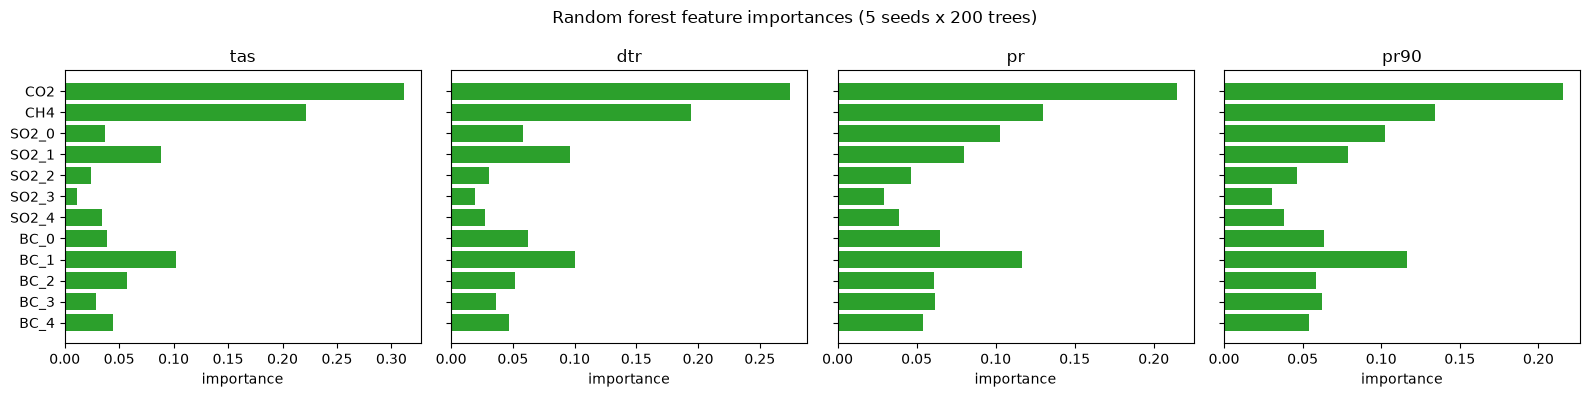

In [14]:
imp = pd.DataFrame({SHORT[var]: np.mean(importances[var], axis=0) for var in TARGETS}, index=FEATURES)

fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for ax, col in zip(axes, imp.columns):
    ax.barh(imp.index[::-1], imp[col][::-1], color="tab:green")
    ax.set_title(col)
    ax.set_xlabel("importance")
fig.suptitle("Random forest feature importances (5 seeds x 200 trees)")
fig.tight_layout()
fig.savefig(f"{FIGS}/week3_rf_importance.png", dpi=150, bbox_inches="tight")
imp.round(3)

## 9. Comparison with the official RF

Written **after** this RF was finished and scored, as the brief suggests ("write your own first, then compare"). Compared
against `baseline_models/Original_RF_model.ipynb`, `baseline_models/RF_model_ESEm.ipynb` (the final official RF, with the
paper's hyperparameters) and `baseline_models/utils.py`.

### What is the same

The 12 features (CO2, CH4, 5 SO2 PCs, 5 BC PCs); one multi-output forest per target that predicts every grid cell; ensemble-mean
targets; precipitation in mm/day; the hyperparameter search space; `bootstrap=True`.

### What is different

| # | Official RF | This notebook |
|---|---|---|
| 1 | `RF_model_ESEm.ipynb` trains on **4 scenarios**: historical, ssp585, ssp126, ssp370 (`Original_RF_model.ipynb` uses all 6) | All **6** training scenarios, like the GP |
| 2 | EOFs from `eofs` with **no latitude weights** (`Eof(X['BC'])`), although the comment above it says √cos(lat) weights are applied | √cos(lat)-weighted PCA, copied from the GP notebook |
| 3 | `RandomizedSearchCV(cv=3)`: 3 contiguous blocks of the concatenated training years; folds don't line up with scenarios | Leave-one-scenario-out CV, EOFs refit in each fold, relative RMSE averaged over folds |
| 4 | `n_estimators` searched (100–300); one forest, `random_state=0` | Fixed 200 trees; 5 seeds, saved prediction = their mean |
| 5 | Chosen: `max_features='auto'` (all features) for every target | Chosen: `max_features='sqrt'` for every target (see the table in section 4) |

### Why our tas score is worse

Our tas total is about 1.5 vs 0.40 published; dtr is better and pr/pr90 slightly worse. To find the cause we refit with the
official choices and scored them on `ssp245` (100 trees, 1 seed). **These runs are diagnostics only: they came after we saw the
`ssp245` scores, so none of them was used to choose the submitted model.**

| Setup | tas spatial | tas global | tas total |
|---|---|---|---|
| Ours (submitted hyperparameters) | 0.250 | 0.220 | 1.35 |
| Ours, but `max_features=1.0` | 0.110 | 0.223 | 1.22 |
| Paper hyperparameters, 6 scenarios | 0.141 | 0.251 | 1.40 |
| Paper hyperparameters, 4 scenarios | 0.165 | 0.125 | 0.79 |
| Paper hyperparameters, 4 scenarios, unweighted EOFs | 0.153 | 0.100 | 0.65 |
| Published | 0.108 | 0.058 | 0.40 |

- **Spatial error** comes mostly from `max_features='sqrt'`: each split sees 3 of 12 features and often misses CO2.
  With all features, tas spatial matches the paper. Our CV could not separate the two: for tas, `sqrt` won on 3 held-out
  scenarios and lost on 3.
- **Global error** comes mostly from the **training scenarios**, not the hyperparameters. A tree predicts a constant in each
  leaf, so it can't interpolate between scenarios. Trained on all 6, the forest's tas global mean stays flat (1.39 K in 2070,
  1.44 K in 2080) and then jumps to 2.47 K in 2090; the truth rises smoothly (1.77, 1.79, 2.19 K). That jump falls inside the
  scored 2080–2100 window. Training on the paper's 4 scenarios moves the jump and halves the global error.
- The rest of the gap (0.100 vs 0.058) is not explained; seed and scikit-learn version differences are likely but untested.
- **dtr is better than published** (16.7 vs 22.5 total). Checked for leakage: `ssp245` is used only for scoring, plots, and
  grid coordinates. A likely reason is that our training set includes `hist-aer`: aerosols drive much of the DTR change, and
  the paper's 4-scenario RF never sees aerosol-only forcing (the 6-scenario diagnostic also beats the 4-scenario one on dtr).

### Notes for the write-up

- The hyperparameters, and how they were chosen without `ssp245`: section 4.
- Seed spread (section 7) is small compared with the gap to the paper: tas total 1.48 ± 0.12.
- Importances (section 8): with `sqrt`, credit is shared across features, so they understate CO2 for tas. Aerosol PCs carry
  more weight for pr and pr90 than for tas.
- Lesson: leave-one-scenario-out CV is the honest way to tune here, but with only 6 scenarios, several of which need
  extrapolation, it is a noisy guide to performance on an interpolation scenario like `ssp245`.